# Python Shiny - App Template
Here we present the base mechanism for building an interactive dashboard, i.e., a [Python-Shiny dashboard](https://shiny.posit.co/py/). 

In this dashboard, we'll read the `NTL-LTER_Lake_Nutrients_PeterPaul_Processed.csv` dataset and allow the user to interactively explore nutrient values over time. The user will select which nutrient to examine from a dropdown menu, limit the time frame of data viewed by a date slider, toggle which lake(s) to view, and also toggle value for different depth classes. 

In this notebook, we'll construct, test, debug the base code before we move it over to the Shiny version. This code will include how we import the csv into a dataframe, how we query the data to mimic user queries via the dashboard widgets, and how the selected data will be plotted. 

**CONDA RECIPE**
```bash
 conda create -n env700-shiny -c conda-forge python=3.12 shiny geopandas pandas matplotlib seaborn folium mapclassify jupyterlab ipykernel
```

In [ ]:
# Import packages
#from datetime import datetime as dt
import pandas as pd
import seaborn as sns

In [10]:
# Read the data into a dataframe
df_nutrients = pd.read_csv(
    'Data/NTL-LTER_Lake_Nutrients_PeterPaul_Processed.csv',
    dtype={'lakeid':'str'},
    parse_dates=['sampledate']
)
df_nutrients.head()

,lakeid,lakename,year4,daynum,sampledate,depth_id,depth,tn_ug,tp_ug,nh34,no23,po4,comments
0,L,Paul Lake,1991,140,1991-05-20,1,0.00,538.0,25.0,NaN,NaN,NaN,NaN
1,L,Paul Lake,1991,140,1991-05-20,2,0.85,285.0,14.0,NaN,NaN,NaN,NaN
2,L,Paul Lake,1991,140,1991-05-20,3,1.75,399.0,14.0,NaN,NaN,NaN,NaN
3,L,Paul Lake,1991,140,1991-05-20,4,3.00,453.0,14.0,NaN,NaN,NaN,NaN
4,L,Paul Lake,1991,140,1991-05-20,5,4.00,363.0,13.0,NaN,NaN,NaN,NaN


In [23]:
# Filtering the data

# Set the "selected" values
start_date = "1995-01-01"
end_date = "1999-12-31"
nutrient = "tp_ug"
depth_ids = [1,2,3]
lake_names = ['Peter Lake', 'Paul Lake']

# Subset the data
df_subset = df_nutrients.loc[
    (df_nutrients['sampledate'] > start_date) &  # Start date
    (df_nutrients['sampledate'] < end_date) &    # End date
    (df_nutrients['depth_id']).isin(depth_ids) & # Depth IDs
    (df_nutrients['lakename']).isin(lake_names), # Depth IDs
]


AttributeError: 'Legend' object has no attribute 'set_labels'

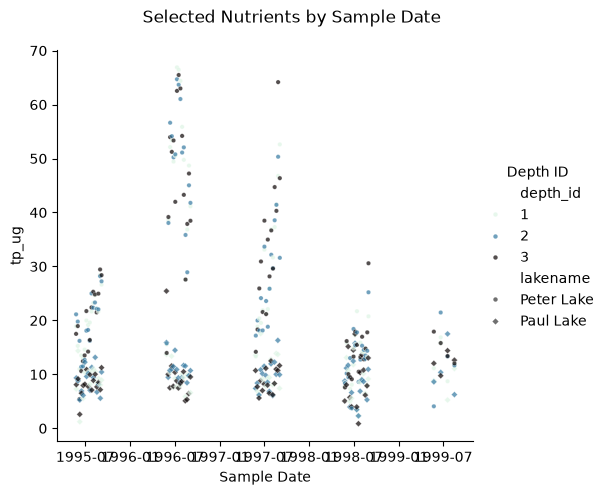

In [ ]:
#Create a plot of selected nutrients by sampledate, with markers colored by depth_id using the inverse mako colormap and different shapes for lakename
the_plot = sns.relplot(
    data = df_subset,
    x='sampledate',
    y=nutrient,
    hue='depth_id',
    style='lakename',#set Peter Lake to circle and Paul Lake to diamond
    markers=['o','D'],
    palette='mako_r',
    s=10,
    alpha=0.7,
);

#Set plot title and axis labels
the_plot.set_axis_labels('Sample Date', nutrient)
the_plot.figure.suptitle('Selected Nutrients by Sample Date')
the_plot.figure.subplots_adjust(top=0.9)

#Set legend names
the_plot.legend.set_title('Depth ID')
# Seaborn already labels the lake markers using the `lakename` values.
# Matplotlib Legend objects do not provide set_labels().
the_plot.legend.set_title('Depth ID / Lake')